<a href="https://colab.research.google.com/github/nareshsinghankit1/CODSOFT_TASKNO/blob/main/Task_3_Sales_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Load and Explore
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("Advertising.csv")
print(df.head())
print(df.info())
print(df.isnull().sum())
print(df.describe())

      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB
None
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64
               TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   15.130500
std     85.854236   14.846809   21.778621    5.283892
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   11.000000
50%    149

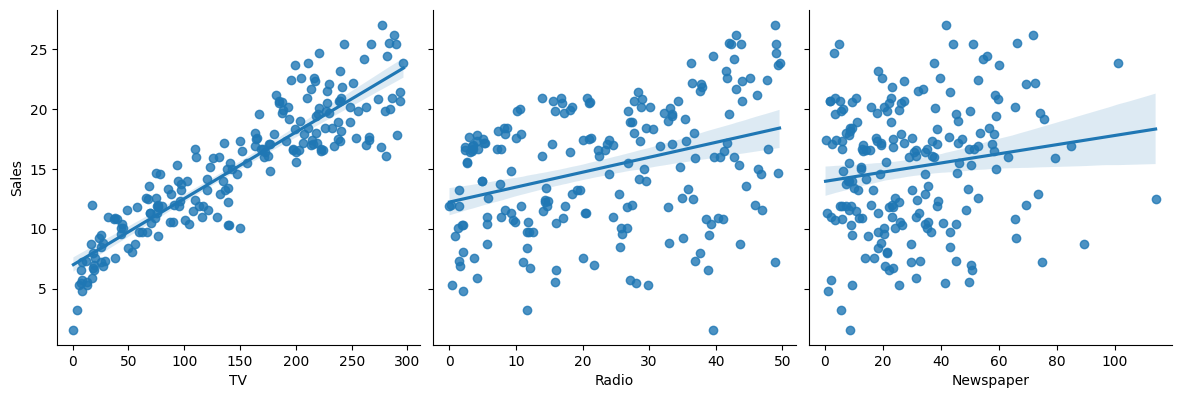

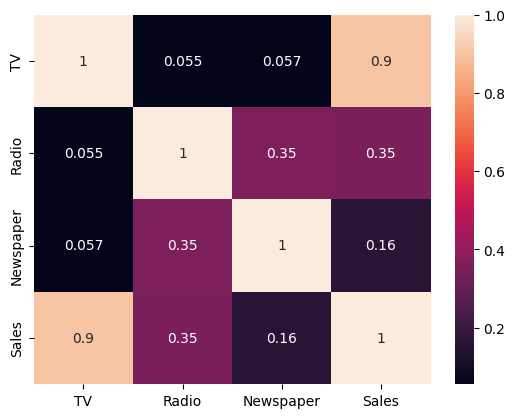

In [3]:
# visulize
sns.pairplot(df, x_vars=["TV", "Radio", "Newspaper"], y_vars="Sales", height=4, kind="reg")
plt.show()

sns.heatmap(df.corr(), annot=True)
plt.show()

In [5]:
#model
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

X = df.drop("Sales", axis=1)
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    cv = cross_val_score(m, X, y, cv=5, scoring="r2").mean()
    print(name, "R2:", round(r2, 3), "RMSE:", round(rmse, 3), "CV R2:", round(cv, 3))

rf = models["Random Forest"]
print(dict(zip(X.columns, rf.feature_importances_.round(3))))

Linear Regression R2: 0.906 RMSE: 1.705 CV R2: 0.895
Random Forest R2: 0.953 RMSE: 1.199 CV R2: 0.942
{'TV': np.float64(0.845), 'Radio': np.float64(0.137), 'Newspaper': np.float64(0.018)}
